## Extract T1w:T2w data for macaque

File names: monkey_myelin_map.pscalar.nii, M132_L_91-area.32k.label.gii, monkey_hierarchy.pscalar.nii\
Extracted from: https://balsa.wustl.edu/N6M9?version=VjBBB\
From scence file: Burt_et_al_2018_Hierarchy\
Original study title: Hierarchy of transcriptomic specialization across human cortex captured by structural neuroimaging topography\
I verified against data in the scene file of the connectome workbench, by selecting the coordinates of each parcel in the viewer
and reading the pscalar value of the myelin map in connectome_wb.

In [1]:
import nibabel as nb
import numpy as np
import pandas as pd
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})

pscalar_file = '../data/raw/macaque/monkey_myelin_map.pscalar.nii'
label_file = '../data/raw/macaque/M132_L_91-area.32k.label.gii'

psc = nb.load(pscalar_file)
t1_t2_data = np.squeeze(psc.get_fdata())

gii = nb.load(label_file)
all_labels = gii.labeltable.labels # Incudes key = 0, which seems to be '???'
# Keep only keys 1–91, sorted by key
labels_1_91 = sorted(
    [lab for lab in all_labels if 1 <= lab.key <= 91],
    key=lambda L: L.key
)
parcel_names = [lab.label for lab in labels_1_91] # now length 91

myelin_series = pd.Series(t1_t2_data, index=parcel_names, name='T1w/T2w')
myelin_series.to_csv('../data/processed/macaque/macaque_t1_t2.csv')


## Reorder so it's in the same order as names in Mejias & Wang 2022

In [2]:
parcel_names = np.array(parcel_names)
area_names_macaque_model = pd.read_excel('../data/raw/macaque/areaList.xlsx')['Name'].tolist() # this file is based on Mejais & Wang 2022
idx_map = {name: i for i, name in enumerate(parcel_names)}
indices = [idx_map[area] for area in area_names_macaque_model]
t1_t2_data_for_macaque_model = t1_t2_data[indices]

## Convert T1w:T2w data to hierarchy values

In [3]:
from scipy.special import erf
# Function from Demirtas et al (2019).
def linearize_map(x):
    """
    linearization function for T1w/T2w maps
    """
    return erf((x - np.mean(x)) / x.std() / np.sqrt(2))

# Apply linearization and normalize (ptp: peak-to-peak)
t1t2_lh_lin = linearize_map(t1_t2_data_for_macaque_model)
hierarchy_from_t1_t2 = (np.max(t1t2_lh_lin) - t1t2_lh_lin) / np.ptp(t1t2_lh_lin)
# Save to CSV
hierarchy_from_t1_t2_df = pd.DataFrame({'Hierarchy_val': hierarchy_from_t1_t2})
hierarchy_from_t1_t2_df.to_csv('../data/processed/macaque/macaque_hierarchy_from_t1_t2.csv')
hierarchy_from_t1_t2_df.to_excel(excel_writer = "../data/processed/macaque/macaque_hierarchy_from_t1_t2.xlsx", index=False, header=False)
print('Hierarchy values, same order as area names in Mejias 2022:\n', hierarchy_from_t1_t2)

Hierarchy values, same order as area names in Mejias 2022:
 [0.         0.05280513 0.1295035  0.5288042  0.06980064 0.41475909
 0.31254434 0.35956065 0.19754683 0.0727244  0.02364356 0.33679296
 0.72424518 0.86473935 0.90938719 0.81263692 0.8657733  0.52191941
 0.05627538 0.77127572 0.73709609 0.34904192 0.33779208 0.42525986
 0.85910471 0.5468578  0.80768162 0.76920343 0.88759148 1.        ]


## Extract hierarchies from Mejias 2022 and correlate with T1:T2 derived

PearsonRResult(statistic=np.float64(0.6403291895049849), pvalue=np.float64(0.00013832262232619266))
Pearson r = 0.640, p = 0.000138
Spearman r = 0.642, p = 0.000132


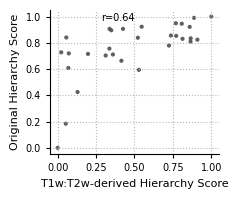

In [4]:
from scipy.stats import pearsonr
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
colors = {
    "grey":   "#4d4d4d", # neutral line/axis color
}
hierarchy_mejias = np.array(pd.read_excel('../data/raw/macaque/hierVals.xlsx', header=None)).squeeze()  # This is also based on Mejias & Wang 2022
print(pearsonr(hierarchy_mejias, hierarchy_from_t1_t2))
# Fit a simple linear trend line
x = hierarchy_from_t1_t2
y = hierarchy_mejias
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")

r_spearman, p_spearman = spearmanr(x, y)
print(f"Spearman r = {r_spearman:.3f}, p = {p_spearman:.3g}")

fig, ax = plt.subplots(figsize=(2.3, 2.0))
ax.scatter(x, y, s=9, alpha=0.9, color=colors['grey'], edgecolor='none')
ax.set_xlabel('T1w:T2w-derived Hierarchy Score')
ax.set_ylabel('Original Hierarchy Score')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r_spearman:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('results/macaque/t1t2hier_vs_spinehier.svg', bbox_inches='tight')
plt.show()

In [5]:
hierarchy_mejias, hierarchy_from_t1_t2

(array([0.        , 0.18428943, 0.42533991, 0.5939034 , 0.60831409,
        0.66341388, 0.70336722, 0.71139488, 0.71547745, 0.71933646,
        0.72766163, 0.75584014, 0.77935302, 0.80935301, 0.82401849,
        0.83036221, 0.83427106, 0.8386962 , 0.8406509 , 0.85312677,
        0.85545344, 0.89536725, 0.90628201, 0.90648715, 0.92158634,
        0.92267981, 0.94540054, 0.94885523, 0.99025583, 1.        ]),
 array([0.        , 0.05280513, 0.1295035 , 0.5288042 , 0.06980064,
        0.41475909, 0.31254434, 0.35956065, 0.19754683, 0.0727244 ,
        0.02364356, 0.33679296, 0.72424518, 0.86473935, 0.90938719,
        0.81263692, 0.8657733 , 0.52191941, 0.05627538, 0.77127572,
        0.73709609, 0.34904192, 0.33779208, 0.42525986, 0.85910471,
        0.5468578 , 0.80768162, 0.76920343, 0.88759148, 1.        ]))

## Compute SLN based on T1:T2 derived hierarchy

In [6]:
# Based on Qingkai Zhu's Feedforward and Feedback Frequency-dependent Interplays in a Large-scale Laminar Model of the Human Cortex
# Master thesis formula: ldiffSLN
hierVal = hierarchy_from_t1_t2 - np.min(hierarchy_from_t1_t2)
hierVal = hierVal / np.max(hierVal)
maxDiff = np.ptp(hierVal)
ldiffSLN = np.zeros((len(hierVal), len(hierVal)))
# i is the target, j is the source
# if target is very low in the hierarchy, the SLN will be close to 0 (small) for that target from a source that is high in hierarchy
for i in range(len(hierVal)):
    for j in range(len(hierVal)):
        ldiffSLN[i, j] = ((hierVal[i] - hierVal[j]) / (2 * maxDiff)) + 0.5

ldiffSLN -= np.diag(np.diag(ldiffSLN)) # Make diagonal elements equal to 0 (there are other self excitatory variables)
ldiffSLN_df = pd.DataFrame(ldiffSLN)
ldiffSLN_df.to_csv('../data/processed/macaque/macaque_t1_t2_SLN.csv', index = False)
ldiffSLN_df.to_excel(excel_writer = "../data/processed/macaque/macaque_t1_t2_SLN.xlsx", index=False, header=False)

## Corelate initial SLN from Jorge with T1-T2 obtained SLN

In [7]:
sln_mejias = np.array(pd.read_excel('../data/raw/macaque/sln.xlsx', header=None)) # SLN from Mejias & Wang 2022
mask = (sln_mejias == 0)
ldiffSLN[mask] = 0 # Need to set elements in SLN equal to zero where there are no connections, same as in Jorge's paper
print(pearsonr(sln_mejias.flatten(), ldiffSLN.flatten()))
corr = pearsonr(sln_mejias.flatten(), ldiffSLN.flatten())[0]
print(corr)

PearsonRResult(statistic=np.float64(0.7703149807729074), pvalue=np.float64(1.151982637241877e-177))
0.7703149807729074


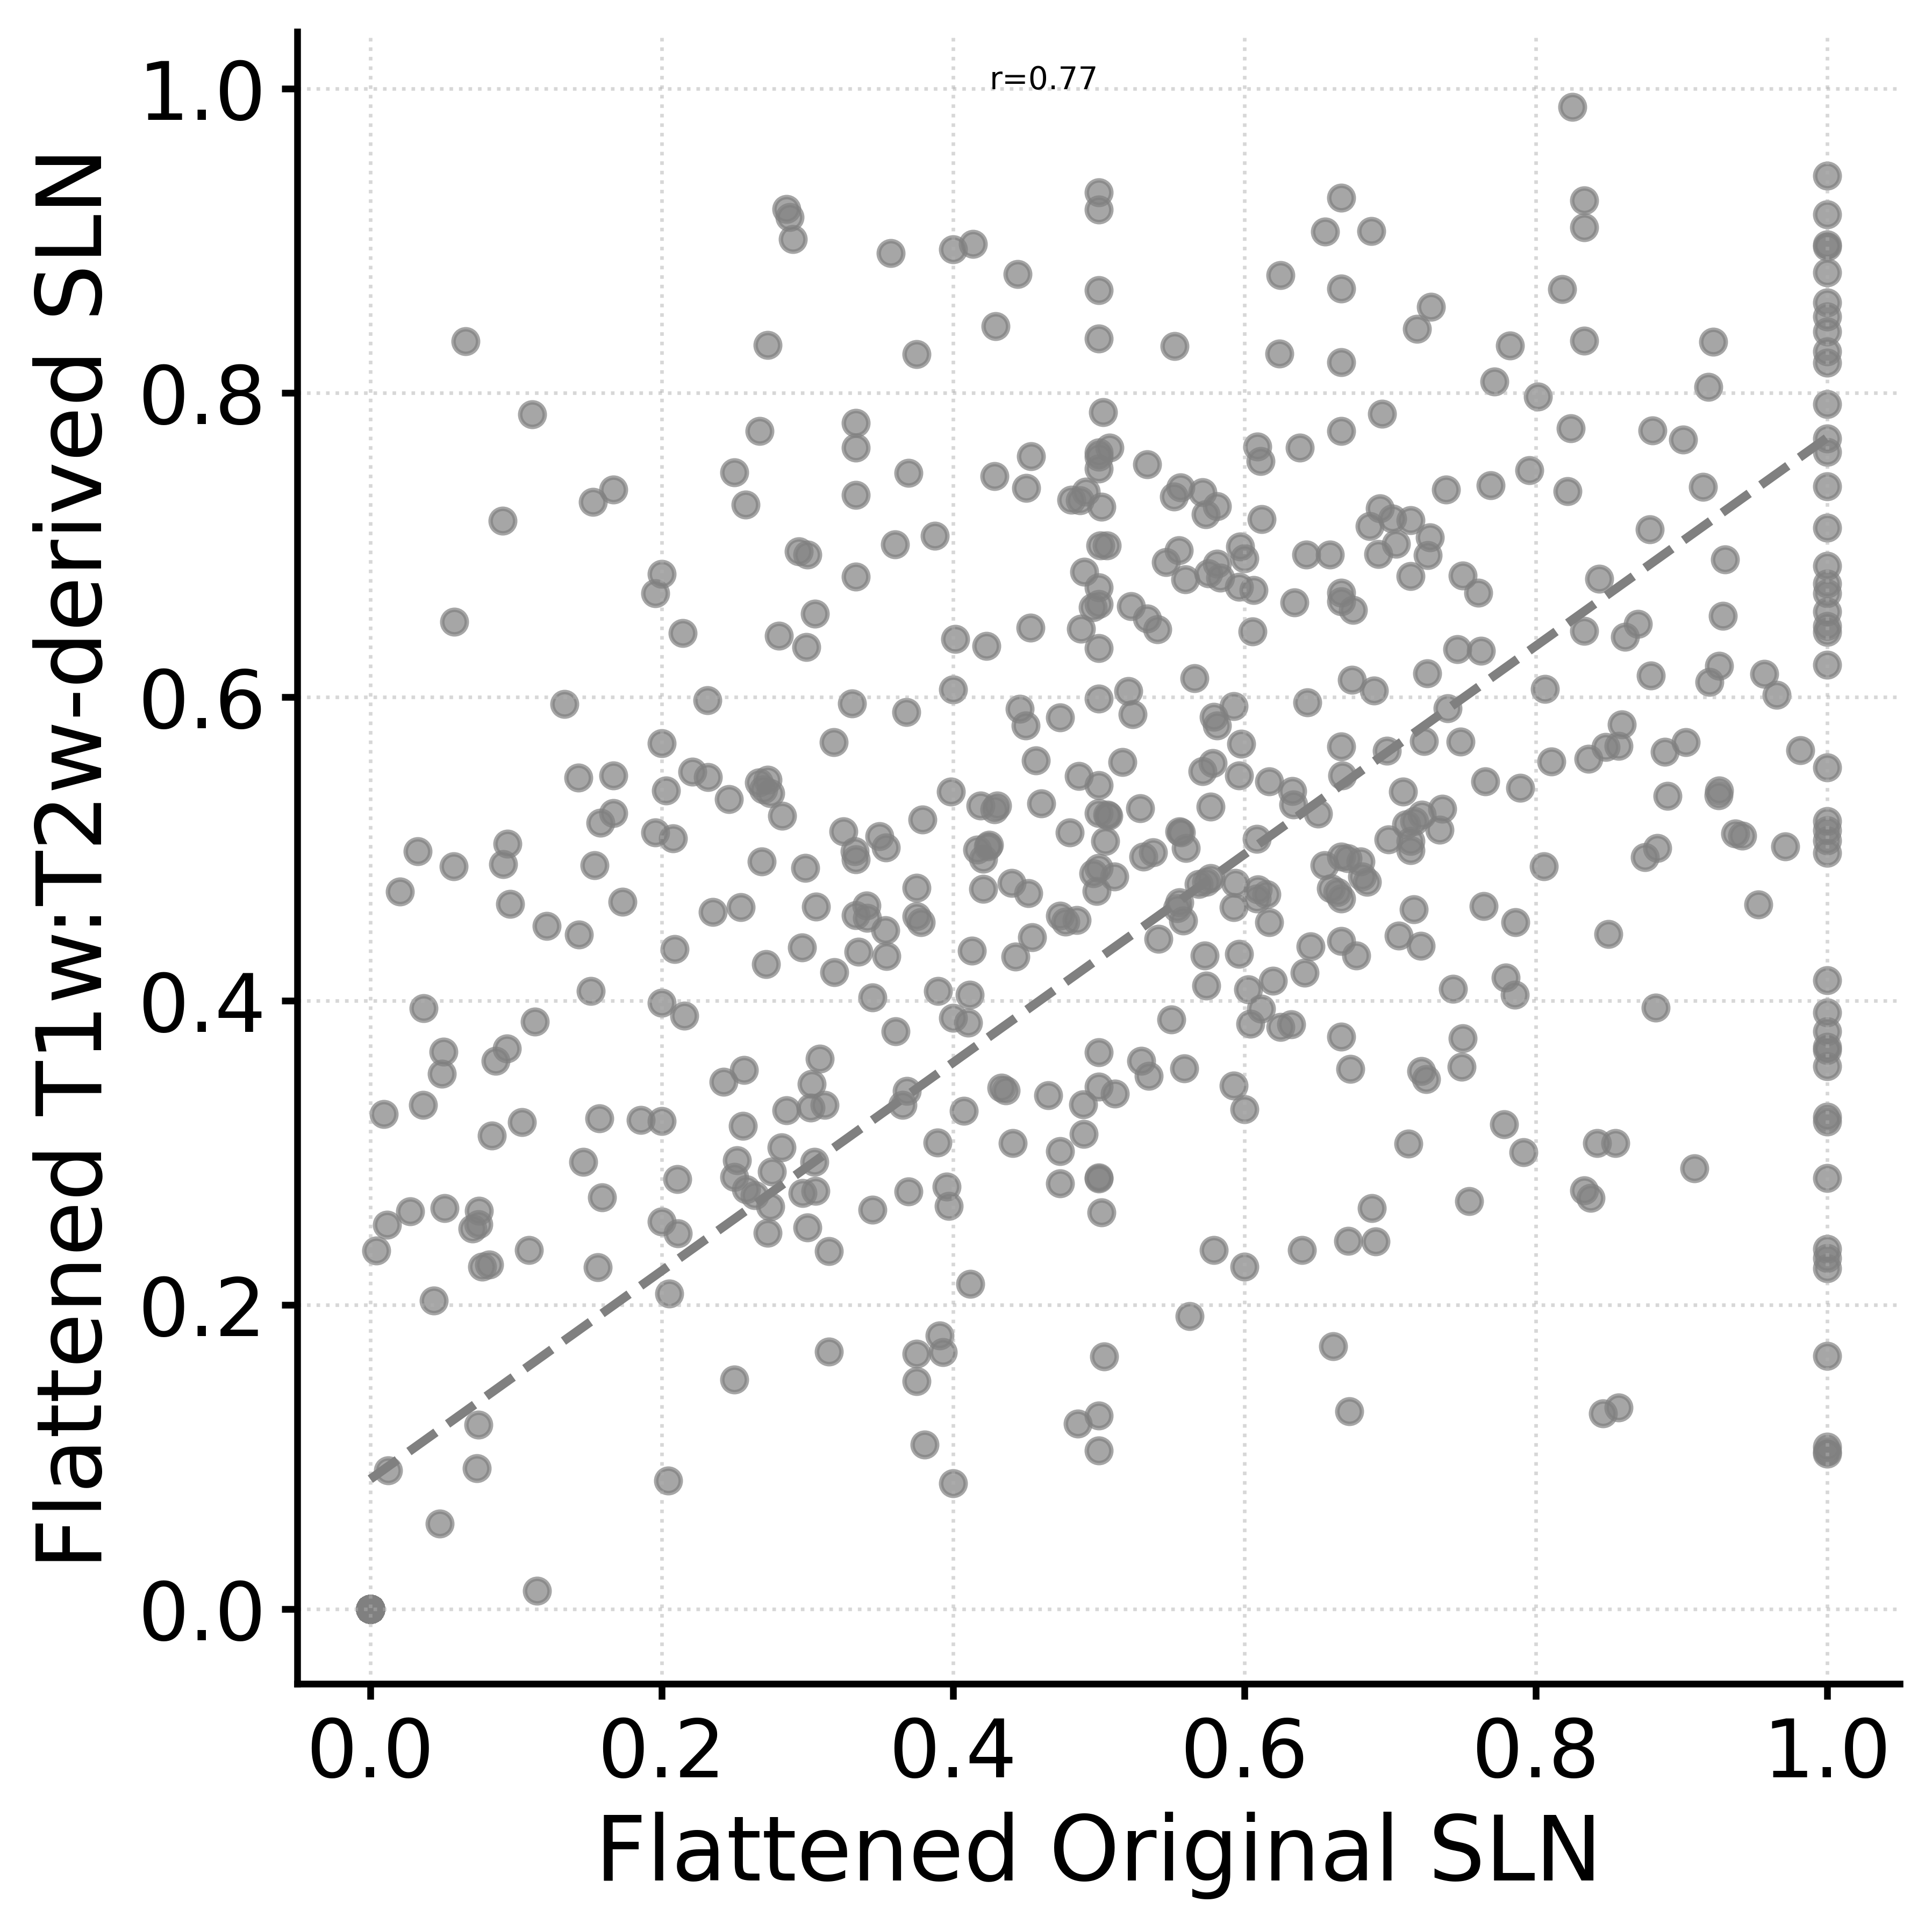

In [8]:
import matplotlib.pyplot as plt
plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.title_fontsize": 16,
    "legend.fontsize": 14,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

slope, intercept = np.polyfit(sln_mejias.flatten(), ldiffSLN.flatten(), 1)
y_line = slope * sln_mejias.flatten() + intercept

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sln_mejias.flatten(), ldiffSLN.flatten(), s=30, alpha=0.7, color='grey')
ax.set_xlabel('Flattened Original SLN')
ax.set_ylabel('Flattened T1w:T2w-derived SLN')
idx = np.argsort(sln_mejias.flatten())
ax.plot(sln_mejias.flatten()[idx], y_line[idx],
         color='grey', linestyle='--', linewidth=2,
         label=f"y = {slope:.2f} x Original_SLN + ({intercept:.2f})")
ax.grid(linestyle=':', alpha=0.5)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.text(
    0.5, 0.98, f"r={corr:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('results/macaque/Macaque_SLN_orig_vs_t1t2.pdf', dpi=1200, bbox_inches='tight')
plt.show()

## Journal-sized version of the flattened-SLN correlation

The same scatter as the cell above, sized to sit next to the macaque all-areas panel of
`../models/macaque/notebooks/run_WM_model.ipynb`: that panel is 2/3 of the 18.4 cm page width by
9 cm, so this one takes the remaining 1/3 (6.13 cm) and is a bit shorter at 7 cm.
Open Sans at 7 pt, as in the other panels. Reuses `sln_mejias`, `ldiffSLN` and `corr` from the
cells above; the styling is applied inside `mpl.rc_context`, so the rcParams set above are
left alone.

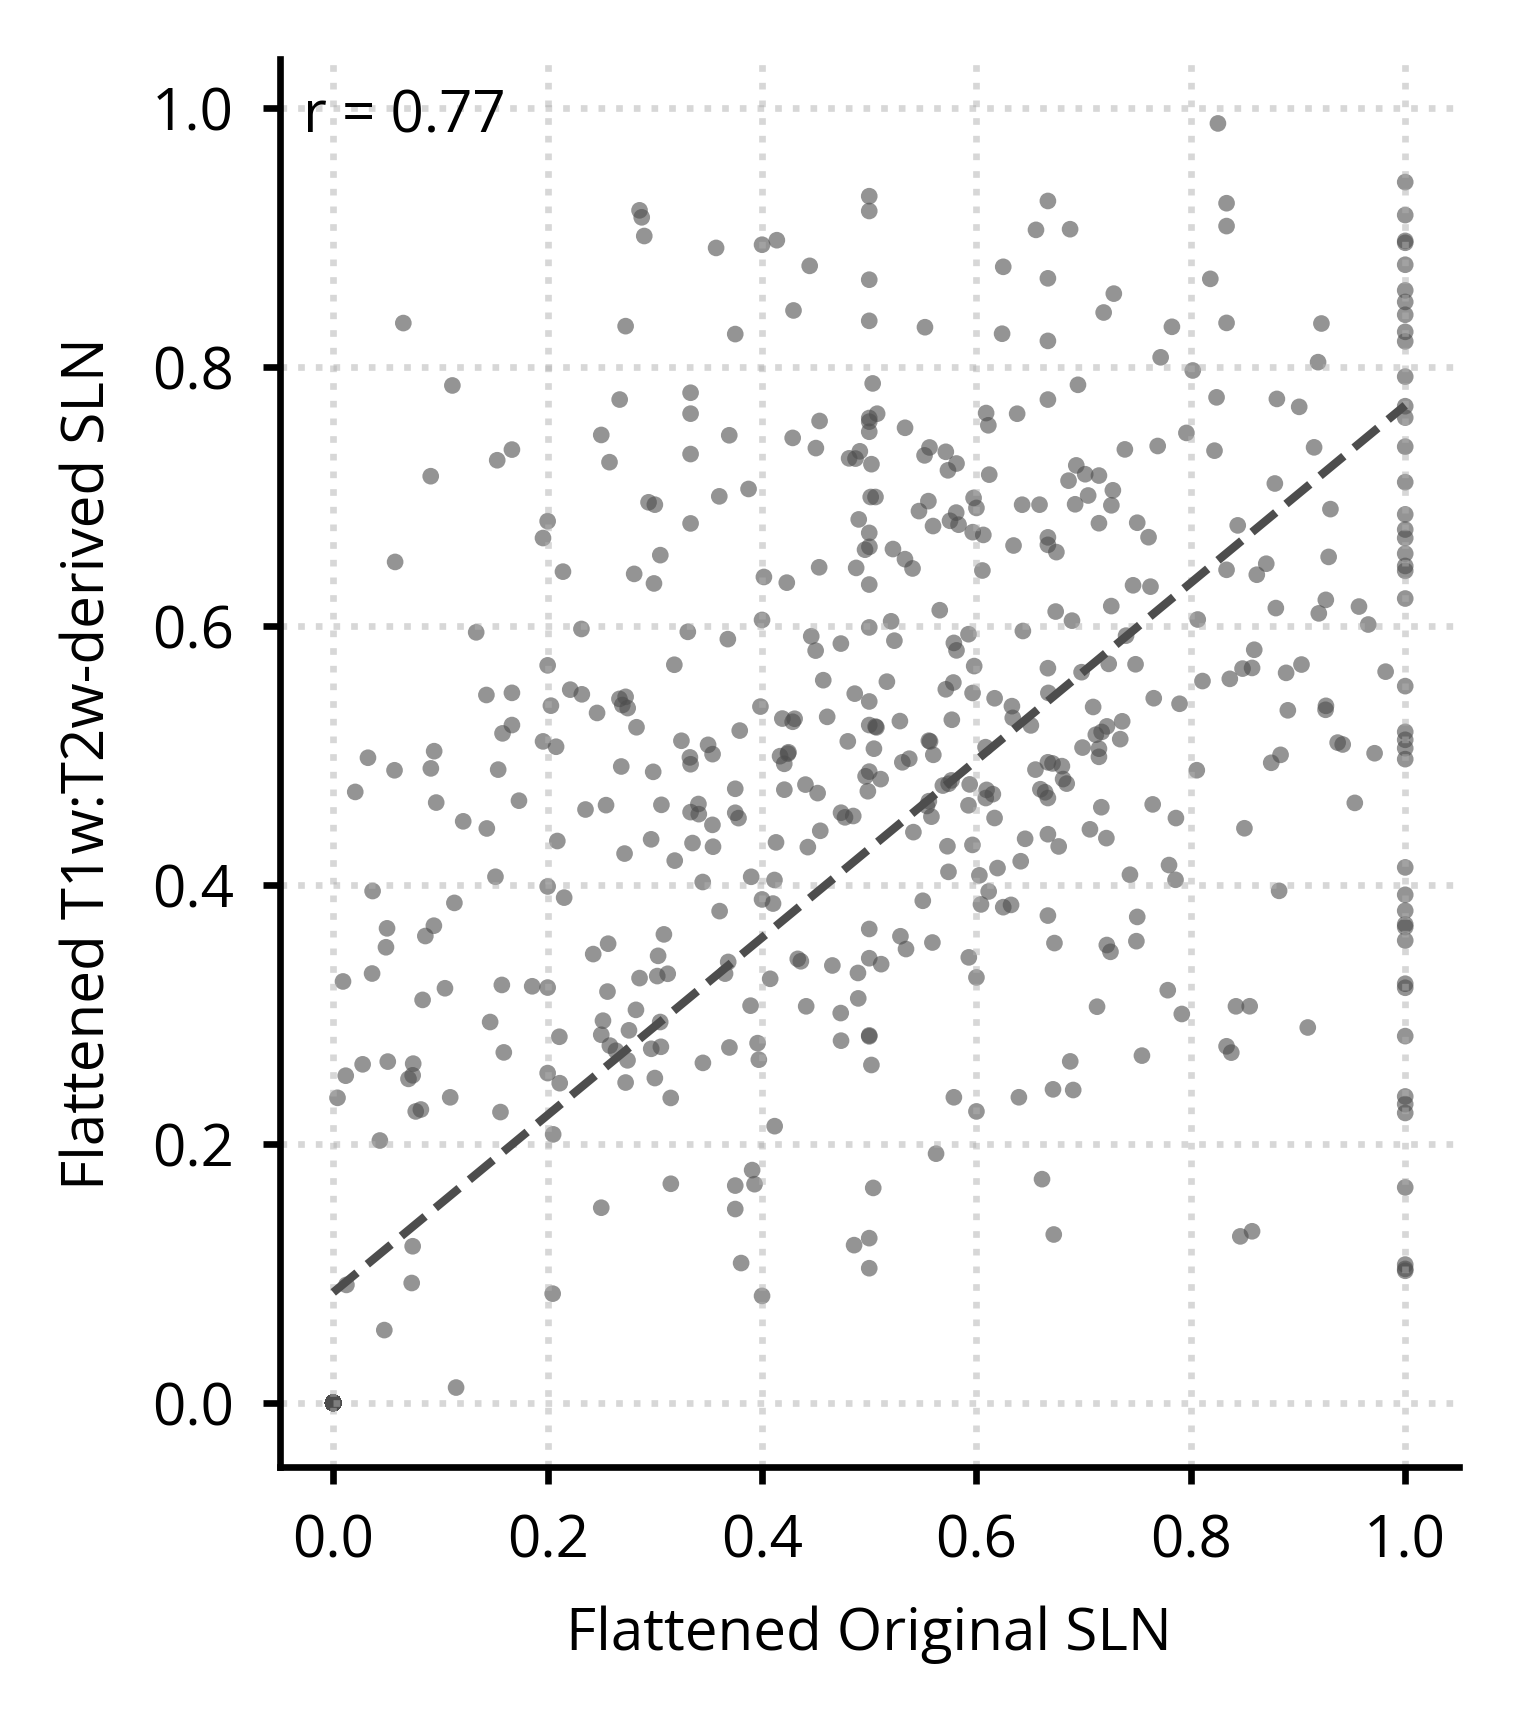

Panel is 6.13 x 7.00 cm  (r = 0.770, slope = 0.69, intercept = 0.09)


In [9]:
# Journal-sized version of the flattened-SLN correlation:
# 1/3 of the 18.4 cm page width (6.13 cm) by 7 cm, Open Sans at 7 pt.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Same style dict as the assembled panels in the Figures/ notebooks. Applied only inside
# the "with" block below, so the rcParams set by the cells above are left alone.
panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 1 / 3 * 18.4 / CM   # the third of the width the all-areas panel leaves free
FIG_H = 7.0 / CM            # a bit less than the 9 cm of that panel

x_sln = sln_mejias.flatten()
y_sln = ldiffSLN.flatten()
slope, intercept = np.polyfit(x_sln, y_sln, 1)
y_line = slope * x_sln + intercept
idx = np.argsort(x_sln)

with mpl.rc_context(panel_style):
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), constrained_layout=True)

    # markers are much smaller than in the cell above: 900 points in a 6 cm wide panel
    ax.scatter(x_sln, y_sln, s=4, alpha=0.6, color=colors['grey'], edgecolor='none')
    ax.plot(x_sln[idx], y_line[idx], color=colors['grey'], linestyle='--', linewidth=1)

    ax.set_xlabel('Flattened Original SLN')
    ax.set_ylabel('Flattened T1w:T2w-derived SLN')
    ax.grid(linestyle=':', alpha=0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # top-left corner: the correlation is positive, so that corner stays empty
    ax.text(0.02, 0.98, f'r = {corr:.2f}', transform=ax.transAxes, va='top', ha='left')

    # no bbox_inches='tight', so the files keep the exact 6.13 x 7 cm size
    fig.savefig('results/macaque/Macaque_SLN_orig_vs_t1t2_journal.svg')
    fig.savefig('results/macaque/Macaque_SLN_orig_vs_t1t2_journal.pdf')
    plt.show()

print(f'Panel is {FIG_W * CM:.2f} x {FIG_H * CM:.2f} cm  (r = {corr:.3f}, '
      f'slope = {slope:.2f}, intercept = {intercept:.2f})')